# 04 - Explainability (SHAP and LIME)

Uses the **same explainer classes as the API** (`src/explain/`), applied to the deployed model, on the
held-out test split.

- **SHAP (TreeSHAP):** exact for tree models; contributions are in **log-odds** and add up to the model output.
- **LIME:** local linear surrogate fitted around one customer; weights are in **probability** units.
  The two are therefore compared by *rank and sign*, not by magnitude.

Sections: global importance, direction of effects, individual explanations, SHAP-vs-LIME agreement,
and a sanity check against a linear model.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent          # notebooks/ lives one level below the project root
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4), "axes.titlesize": 11})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [2]:
import shap
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split

from src.data.load import load_raw
from src.data.preprocess import clean
from src.features.build_features import FEATURES, LABELS, TARGET, build_features
from src.models.predict import load_bundle
from src.models.train import make_logreg
from src.explain.shap_explainer import ShapExplainer
from src.explain.lime_explainer import LimeExplainer

bundle = load_bundle()
shap_e, lime_e = ShapExplainer(bundle), LimeExplainer(bundle)
df = clean(load_raw())
X, y = build_features(df), df[TARGET].astype(int).reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_test = X_test.reset_index(drop=True); y_test = y_test.reset_index(drop=True)
proba = bundle.pipeline.predict_proba(X_test)[:, 1]
print("model:", bundle.version, "| test customers:", len(X_test))

expl = shap_e.explain(X_test)
S = pd.DataFrame([{v["feature"]: v["contribution"] for v in e["values"]} for e in expl])[FEATURES]   # SHAP, log-odds
base = expl[0]["base_value"]
err = np.abs(base + S.sum(axis=1) - np.log(proba / (1 - proba))).max()
print(f"SHAP additivity: max |base + sum(SHAP) - logit(p)| over test set = {err:.1e}")

model: xgboost-20261117-f6239cb7 | test customers: 1409


SHAP additivity: max |base + sum(SHAP) - logit(p)| over test set = 8.7e-06


## 1. Global importance

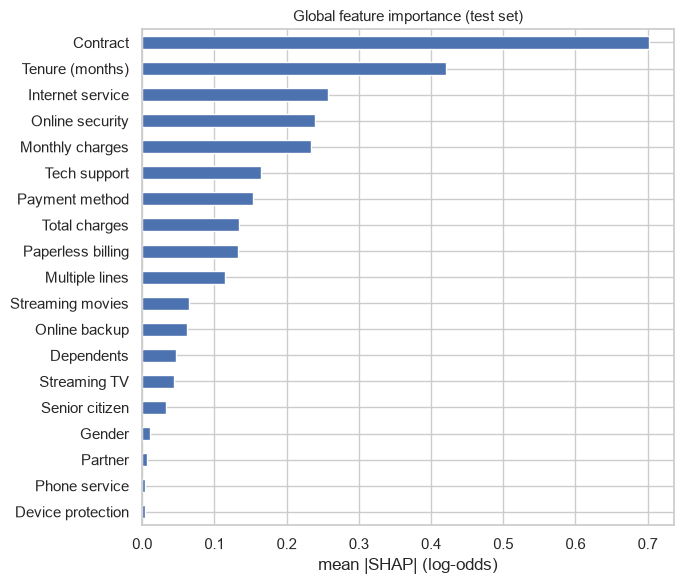

top 8:
Contract            0.701
Tenure (months)     0.421
Internet service    0.258
Online security     0.239
Monthly charges     0.233
Tech support        0.164
Payment method      0.154
Total charges       0.135

share of total importance: top 3 = 49%, bottom 6 = 3.6%
bottom 6: Device protection, Phone service, Partner, Gender, Senior citizen, Streaming TV


In [3]:
imp = S.abs().mean().rename(index=LABELS).sort_values()
imp.plot.barh(figsize=(7, 6), color="#4c72b0")
plt.xlabel("mean |SHAP| (log-odds)"); plt.title("Global feature importance (test set)"); plt.tight_layout(); plt.show()
print("top 8:"); print(imp.sort_values(ascending=False).head(8).round(3).to_string())
print(f"\nshare of total importance: top 3 = {imp.sort_values(ascending=False).head(3).sum() / imp.sum():.0%}, "
      f"bottom 6 = {imp.sort_values().head(6).sum() / imp.sum():.1%}")
print("bottom 6:", ", ".join(imp.sort_values().head(6).index))

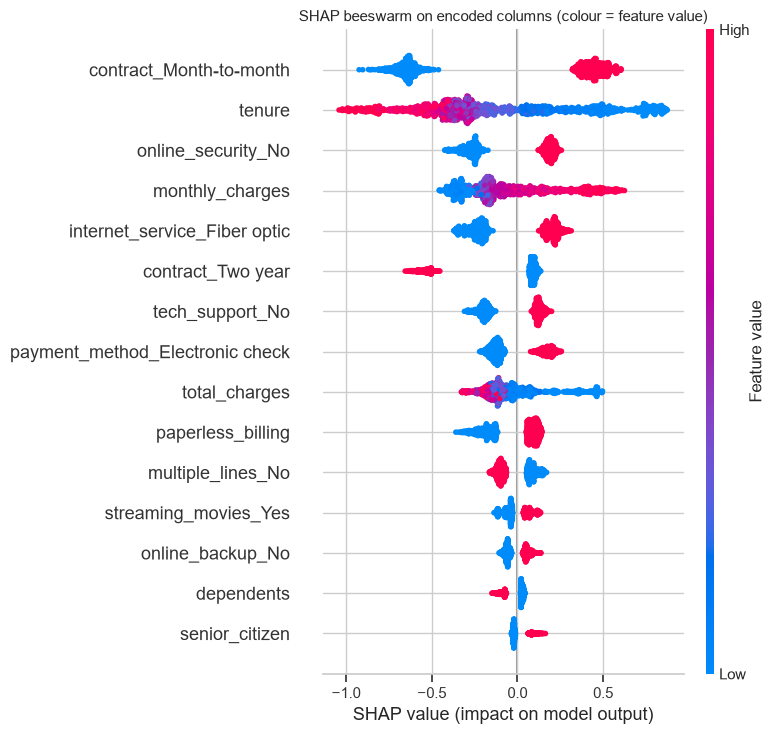

In [4]:
enc = shap_e.prep.transform(X_test)
names = list(shap_e.prep.get_feature_names_out())
sv = shap_e.explainer.shap_values(enc)
shap.summary_plot(sv, enc, feature_names=names, max_display=15, show=False)
plt.title("SHAP beeswarm on encoded columns (colour = feature value)"); plt.tight_layout(); plt.show()

## 2. Direction of effects

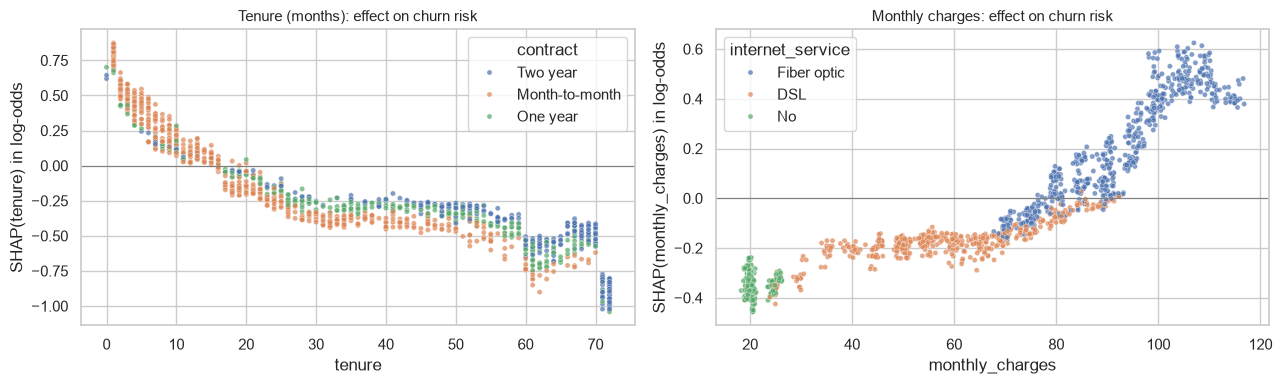

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (feat, hue) in zip(axes, [("tenure", "contract"), ("monthly_charges", "internet_service")]):
    sns.scatterplot(x=X_test[feat], y=S[feat], hue=X_test[hue], s=14, alpha=0.7, ax=ax)
    ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel(f"SHAP({feat}) in log-odds"); ax.set_title(f"{LABELS[feat]}: effect on churn risk")
plt.tight_layout(); plt.show()

In [6]:
for feat in ["contract", "internet_service", "payment_method", "tech_support", "online_security"]:
    g = S[feat].groupby(X_test[feat]).agg(["mean", "size"]).round(3)
    print(f"{LABELS[feat]}  (mean SHAP in log-odds; + = towards churn)"); print(g.to_string()); print()

Contract  (mean SHAP in log-odds; + = towards churn)
                 mean  size
contract                   
Month-to-month  0.536   773
One year       -0.510   300
Two year       -1.251   336

Internet service  (mean SHAP in log-odds; + = towards churn)
                   mean  size
internet_service             
DSL              -0.270   484
Fiber optic       0.239   613
No               -0.277   312

Payment method  (mean SHAP in log-odds; + = towards churn)
                            mean  size
payment_method                        
Bank transfer (automatic) -0.127   300
Credit card (automatic)   -0.146   309
Electronic check           0.183   474
Mailed check              -0.143   326

Tech support  (mean SHAP in log-odds; + = towards churn)
                      mean  size
tech_support                    
No                   0.129   702
No internet service -0.207   312
Yes                 -0.193   395

Online security  (mean SHAP in log-odds; + = towards churn)
                 

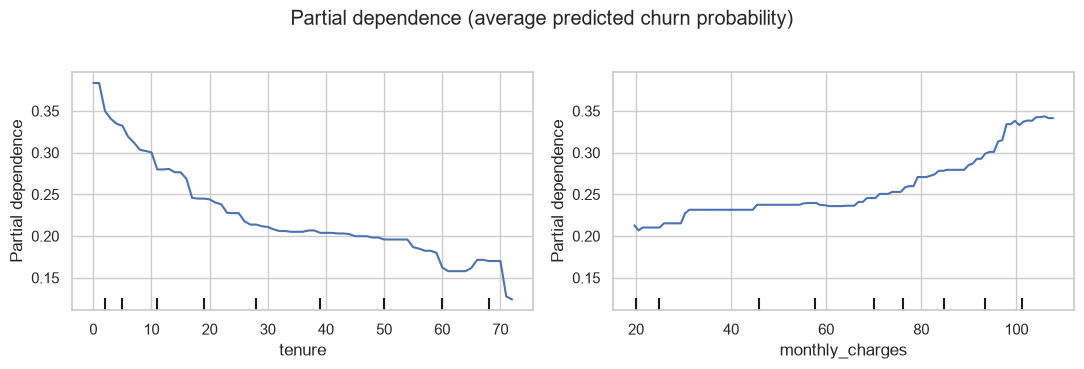

In [7]:
from sklearn.inspection import PartialDependenceDisplay
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
PartialDependenceDisplay.from_estimator(bundle.pipeline, X_test, ["tenure", "monthly_charges"], kind="average", ax=ax)
plt.suptitle("Partial dependence (average predicted churn probability)", y=1.02); plt.tight_layout(); plt.show()

## 3. Individual explanations

The highest-risk and lowest-risk customers of the test set, explained by both methods.

test customer #1090: churn probability 90.1% | actually churned: True
  Contract=Month-to-month, Tenure (months)=1.0, Internet service=Fiber optic, Payment method=Electronic check, Tech support=No, Monthly charges=95.1


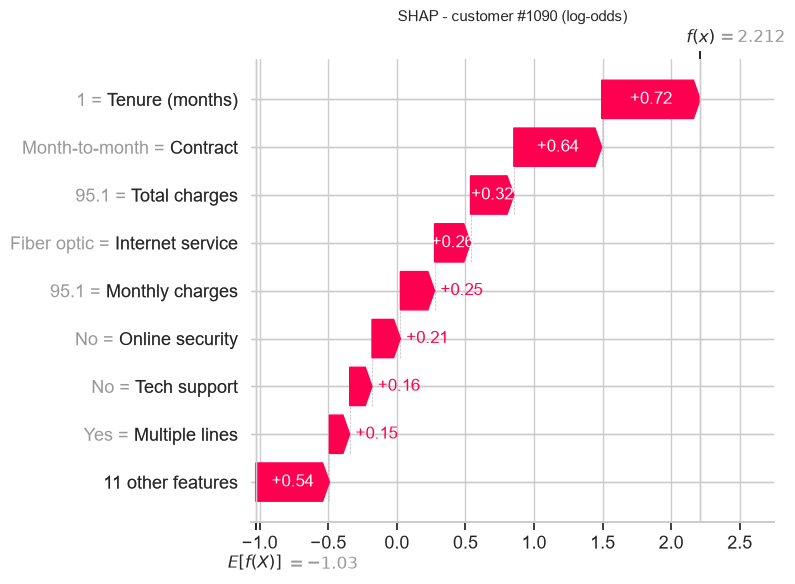

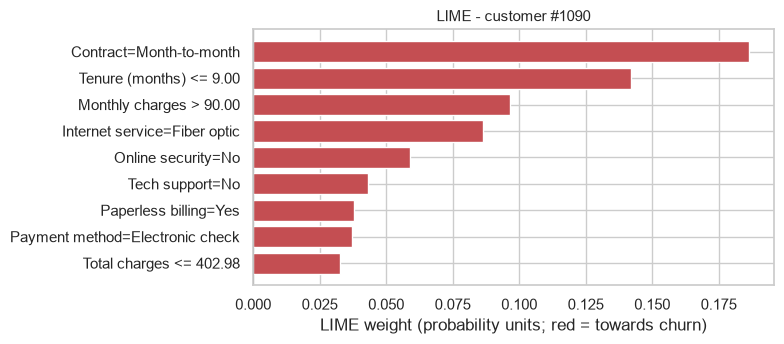

In [8]:
def describe(i):
    r = X_test.iloc[i]
    print(f"test customer #{i}: churn probability {proba[i]:.1%} | actually churned: {bool(y_test.iloc[i])}")
    print("  " + ", ".join(f"{LABELS[f]}={r[f]}" for f in ["contract", "tenure", "internet_service", "payment_method", "tech_support", "monthly_charges"]))

def waterfall(i):
    vals = {v["feature"]: v for v in expl[i]["values"]}
    ex = shap.Explanation(
        values=np.array([vals[f]["contribution"] for f in FEATURES]), base_values=base,
        data=np.array([str(vals[f]["value"]) for f in FEATURES], dtype=object), feature_names=[LABELS[f] for f in FEATURES])
    shap.plots.waterfall(ex, max_display=9, show=False)
    plt.title(f"SHAP - customer #{i} (log-odds)"); plt.tight_layout(); plt.show()

def lime_bar(i, top=9):
    e = lime_e.explain(X_test.iloc[[i]])
    v = pd.DataFrame(e["values"]).head(top).iloc[::-1]
    plt.figure(figsize=(8, 3.6))
    plt.barh(v["rule"], v["contribution"], color=np.where(v["contribution"] > 0, "#c44e52", "#4c72b0"))
    plt.axvline(0, color="grey", lw=0.8); plt.xlabel("LIME weight (probability units; red = towards churn)")
    plt.title(f"LIME - customer #{i}"); plt.tight_layout(); plt.show()
    return e

hi, lo = int(np.argmax(proba)), int(np.argmin(proba))
describe(hi); waterfall(hi); _ = lime_bar(hi)

test customer #1273: churn probability 1.0% | actually churned: False
  Contract=Two year, Tenure (months)=72.0, Internet service=No, Payment method=Bank transfer (automatic), Tech support=No internet service, Monthly charges=20.3


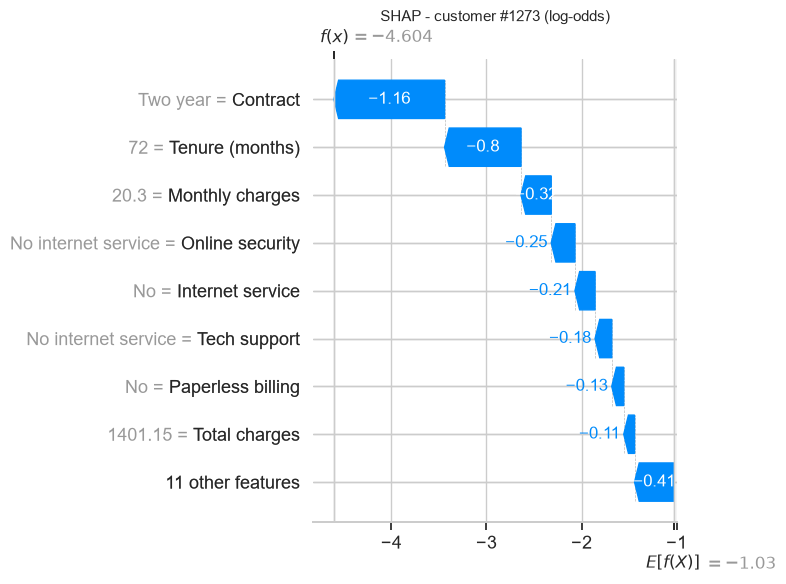

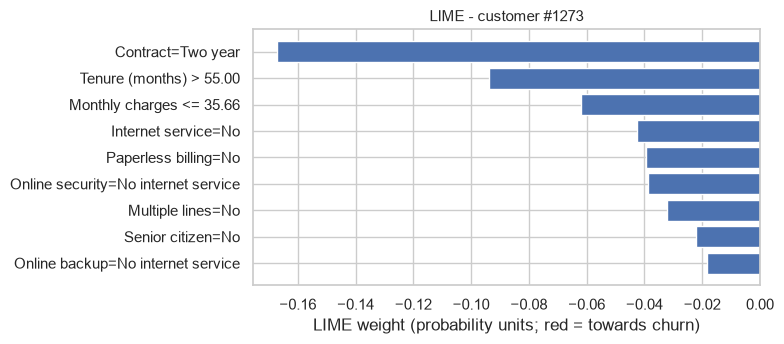

In [9]:
describe(lo); waterfall(lo); _ = lime_bar(lo)

## 4. How much do SHAP and LIME agree?

For 250 random test customers, compare the two explanations per customer: Spearman correlation of
absolute importances (all 19 features), overlap of the top-3 features, and sign agreement on the
features SHAP ranks in its top 5.

Spearman (|SHAP| vs |LIME|, 19 features): mean 0.84, median 0.85, 10th percentile 0.76
top-3 overlap: mean 2.26 of 3 | all three shared in 32% of customers | at least two shared in 93%
sign agreement on SHAP top-5 features: mean 98% | identical for all 5 in 92% of customers

SHAP top-3 features most often missing from LIME's top-3:
Online security     55
Tenure (months)     48
Total charges       28
Internet service    19
Contract            10


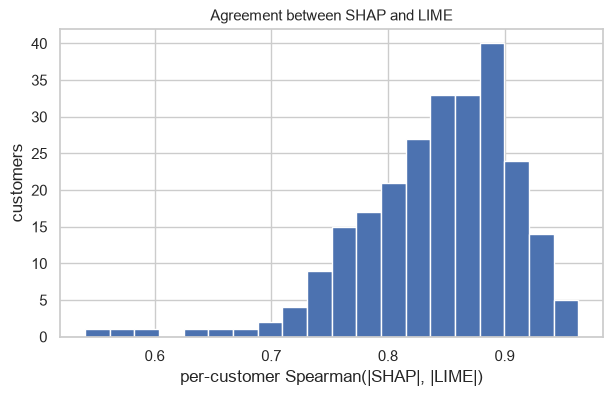

In [10]:
rng = np.random.default_rng(42)
idx = rng.choice(len(X_test), 250, replace=False)
L = pd.DataFrame([{v["feature"]: v["contribution"] for v in lime_e.explain(X_test.iloc[[i]])["values"]} for i in idx])[FEATURES]
Ss = S.iloc[idx].reset_index(drop=True)

rho, top3, sign = [], [], []
miss = pd.Series(0, index=FEATURES)
for k in range(len(idx)):
    s, l = Ss.iloc[k], L.iloc[k]
    rho.append(spearmanr(s.abs(), l.abs())[0])
    ts, tl = set(s.abs().nlargest(3).index), set(l.abs().nlargest(3).index)
    top3.append(len(ts & tl))
    miss[list(ts - tl)] += 1
    top5 = s.abs().nlargest(5).index
    sign.append((np.sign(s[top5]) == np.sign(l[top5])).mean())
rho, top3, sign = np.array(rho), np.array(top3), np.array(sign)
print(f"Spearman (|SHAP| vs |LIME|, 19 features): mean {rho.mean():.2f}, median {np.median(rho):.2f}, 10th percentile {np.percentile(rho, 10):.2f}")
print(f"top-3 overlap: mean {top3.mean():.2f} of 3 | all three shared in {np.mean(top3 == 3):.0%} of customers | at least two shared in {np.mean(top3 >= 2):.0%}")
print(f"sign agreement on SHAP top-5 features: mean {sign.mean():.0%} | identical for all 5 in {np.mean(sign == 1):.0%} of customers")
print("\nSHAP top-3 features most often missing from LIME's top-3:"); print(miss.sort_values(ascending=False).head(5).rename(index=LABELS).to_string())
plt.hist(rho, bins=20, color="#4c72b0"); plt.xlabel("per-customer Spearman(|SHAP|, |LIME|)"); plt.ylabel("customers"); plt.title("Agreement between SHAP and LIME"); plt.show()

## 5. Sanity check against a linear model

A logistic regression gives an independent view of global importance: its contribution for a feature is
`coefficient x (value - mean)`, summed over a feature's one-hot columns. If both models learned the same
signal, the *rankings* should be similar (magnitudes are in different units).

In [11]:
lr = make_logreg().fit(X_train, y_train)
Z = lr.named_steps["prep"].transform(X_test)
coef = lr.named_steps["model"].coef_[0]
lr_feat = pd.Series(np.abs(((Z - Z.mean(axis=0)) * coef) @ shap_e.group).mean(axis=0), index=FEATURES)
shap_feat = S.abs().mean()
rho_g = spearmanr(shap_feat, lr_feat)[0]
print(f"Spearman between XGBoost mean|SHAP| and logistic-regression importance across the 19 features: {rho_g:.2f}")
cmp = pd.DataFrame({"SHAP rank": shap_feat.rank(ascending=False).astype(int), "LogReg rank": lr_feat.rank(ascending=False).astype(int)}).rename(index=LABELS)
cmp["difference"] = (cmp["SHAP rank"] - cmp["LogReg rank"]).abs()
print("\nlargest rank disagreements:"); print(cmp.sort_values("difference", ascending=False).head(6).to_string())
print("\ntop 5 by SHAP:", list(cmp.sort_values("SHAP rank").head(5).index))
print("top 5 by LogReg:", list(cmp.sort_values("LogReg rank").head(5).index))

Spearman between XGBoost mean|SHAP| and logistic-regression importance across the 19 features: 0.84

largest rank disagreements:
                   SHAP rank  LogReg rank  difference
Streaming TV              14            7           7
Tech support               6           11           5
Streaming movies          11            6           5
Device protection         19           14           5
Online security            4            8           4
Paperless billing          9           12           3

top 5 by SHAP: ['Contract', 'Tenure (months)', 'Internet service', 'Online security', 'Monthly charges']
top 5 by LogReg: ['Tenure (months)', 'Internet service', 'Monthly charges', 'Contract', 'Total charges']


## Findings

- **SHAP is exactly additive:** `base + sum(SHAP)` reproduces the model's log-odds to 9e-6 on all 1,409 test customers.
- **Contract dominates:** mean |SHAP| 0.70, then tenure 0.42, internet service 0.26, online security 0.24 and monthly charges 0.23. The top 3 features carry 49% of total importance; the bottom 6 (device protection, phone service, partner, gender, senior citizen, streaming TV) carry 3.6%.
- **Effects point the way the EDA suggested:** month-to-month +0.54 log-odds vs one-year -0.51 and two-year -1.25; fibre optic +0.24 vs DSL -0.27; electronic check +0.18 vs -0.13 to -0.15 for the other payment methods; no tech support +0.13 vs -0.19 with it; no online security +0.19 vs -0.27 with it.
- **Raw association is not model contribution:** senior citizens churn at 41.7% in the EDA, yet `senior_citizen` is in the bottom 6 here. Once contract, tenure, internet service and charges are known, it adds little.
- **Individual explanations are readable:** the riskiest test customer (90.1%: month-to-month, 1 month tenure, fibre, electronic check) did churn; the safest (1.0%: two-year, 72 months, no internet) did not.
- **SHAP and LIME agree well on rank and direction, less on exact top-3:** per-customer Spearman 0.84 on average (10th percentile 0.76); signs agree on 98% of SHAP's top-5 features (all five in 92% of customers); at least two of the top-3 features are shared for 93% of customers but all three for only 32%. The features SHAP puts in its top-3 that LIME misses most often are online security (55 of 250 customers), tenure (48) and total charges (28). A plausible reason (not tested here) is that LIME discretises numeric features into bins and fits a sparse local linear model, which splits importance differently.
- **Independent check:** the model's global importance ranking correlates 0.84 (Spearman) with a logistic regression's, and four of the five top features are shared. The largest disagreements are the streaming add-ons (the linear model ranks them higher) and tech support / online security (SHAP ranks them higher).

## Caveats

- These are *associations learned by a predictive model*, not causal effects: "month-to-month raises churn risk" does not mean forcing customers onto a longer contract would reduce churn.
- Importances are computed on 1,409 test customers; small differences between adjacent ranks are not meaningful.
- The `shap` library's own `expected_value` is ~0.004 log-odds off with XGBoost 3.x, so `ShapExplainer` takes the baseline from XGBoost directly (see `src/explain/shap_explainer.py`).